# 02 · Where does the current model go wrong?

The Stage 2 model earns £33 per battery per year against a £271 ceiling. Before changing
anything, find out *where* and *why* it loses money:

1. How accurate is it, against simple alternatives?
2. When is it wrong: time of day, season?
3. Is its uncertainty honest (does the p10–p90 band hold 80% of outcomes)?
4. Why does it flatten the daily shape?
5. What is it relying on?
6. Which days cost the most £, and what do they look like?

Inputs: the test-window forecasts from `make backtest` (`data/backtest/`), the history, and the
last model the backtest trained. Nothing here touches the test window to *choose* anything;
it only describes the existing model.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import style

from flexcast.backtest import feature_table
from flexcast.history import History
from flexcast.models.base import load_model
from flexcast.models.registry import MODELS
from flexcast.settlement import LONDON
from flexcast.storage import Storage

style.use()
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
store = Storage(f"file://{ROOT / 'data'}")
history = History.load(store)

# The baseline experiment's outputs (`flexcast backtest --experiment baseline`).
forecasts = store.read_parquet("backtest/experiments/baseline/forecasts.parquet")
daily = store.read_parquet("backtest/experiments/baseline/daily.parquet")
lgbm = forecasts[forecasts["strategy"] == "lgbm_quantile"].copy()
naive = forecasts[forecasts["strategy"] == "naive_last_day"].copy()
for f in (lgbm, naive):
    f["hour"] = f["start_time"].dt.tz_convert(LONDON).dt.hour
    f["month"] = f["start_time"].dt.tz_convert(LONDON).dt.month
    f["error"] = f["p50"] - f["actual"]
print(
    f"test window: {lgbm.target_date.min()} to {lgbm.target_date.max()}, {len(lgbm):,} half-hours"
)

test window: 2025-10-20 to 2026-10-19, 17,520 half-hours


## 1. Accuracy against simple alternatives

In [2]:
y = lgbm["actual"]


def scores(pred: pd.Series) -> dict[str, float]:
    err = pred.to_numpy() - y.to_numpy()
    ss_res, ss_tot = (err**2).sum(), ((y - y.mean()) ** 2).sum()
    return {
        "MAE £/MWh": np.abs(err).mean(),
        "R²": 1 - ss_res / ss_tot,
        "correlation": np.corrcoef(pred, y)[0, 1] if pred.std() > 0 else np.nan,
    }


table = pd.DataFrame(
    {
        "LightGBM p50": scores(lgbm["p50"]),
        "copy last complete day": scores(naive["p50"].set_axis(lgbm.index)),
        "always predict the average": scores(pd.Series(y.mean(), index=y.index)),
    }
).T
table.style.format("{:.2f}")

,MAE £/MWh,R²,correlation
LightGBM p50,30.59,0.38,0.63
copy last complete day,44.31,-0.38,0.31
always predict the average,39.02,0.00,nan


The model has real signal (R² ≈ 0.4) and beats both alternatives clearly on error. Copying a
recent day is *worse than predicting the average*.

## 2. When is it wrong?

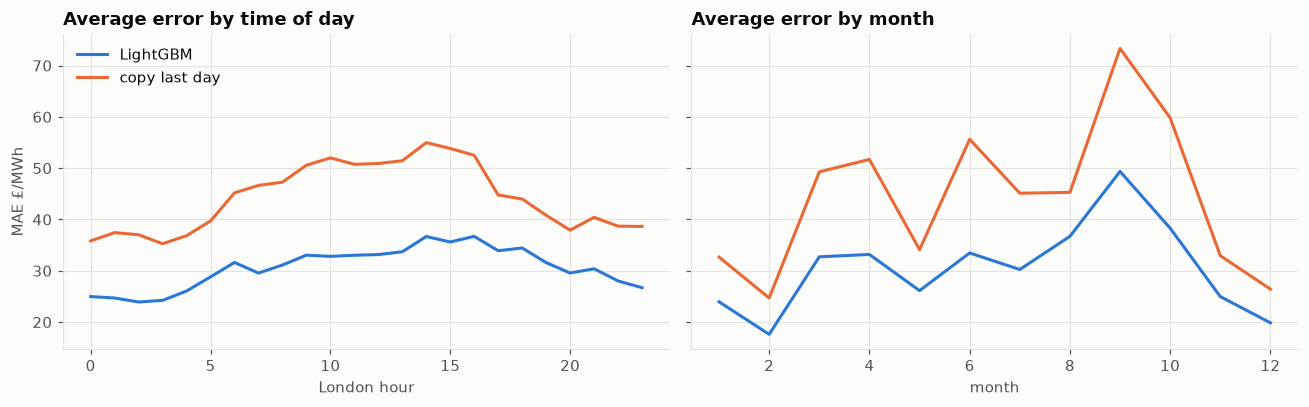

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, key, xlabel in ((axes[0], "hour", "London hour"), (axes[1], "month", "month")):
    for name, f, color in (("LightGBM", lgbm, style.BLUE), ("copy last day", naive, style.ORANGE)):
        mae = f.groupby(key)["error"].apply(lambda e: e.abs().mean())
        ax.plot(mae.index, mae.values, color=color, label=name)
    ax.set(xlabel=xlabel)
axes[0].set(title="Average error by time of day", ylabel="MAE £/MWh")
axes[1].set(title="Average error by month")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

Errors are largest in the evening peak (the spikes) and in winter, exactly where the money is.

## 3. Is the uncertainty honest?

A p10–p90 band should contain 80% of outcomes, with 10% falling below and 10% above.

inside band 66% (target 80%) · below p10 12% (target 10%) · above p90 22% (target 10%)


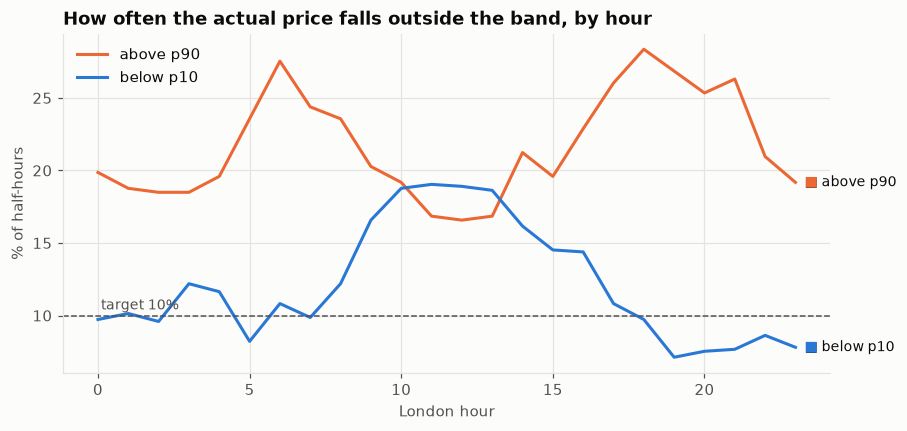

In [4]:
below = (lgbm["actual"] < lgbm["p10"]).mean()
above = (lgbm["actual"] > lgbm["p90"]).mean()
print(
    f"inside band {1 - below - above:.0%} (target 80%) · below p10 {below:.0%} (target 10%) · "
    f"above p90 {above:.0%} (target 10%)"
)

cov = (
    lgbm.assign(below=lgbm.actual < lgbm.p10, above=lgbm.actual > lgbm.p90)
    .groupby("hour")[["below", "above"]]
    .mean()
    * 100
)
fig, ax = plt.subplots()
for col, color, label in (("above", style.ORANGE, "above p90"), ("below", style.BLUE, "below p10")):
    ax.plot(cov.index, cov[col], color=color, label=label)
    style.label_end(ax, cov.index[-1], cov[col].iloc[-1], label, color)
ax.axhline(10, color=style.TEXT_2, linewidth=1, linestyle="--")
ax.annotate(
    "target 10%", (0, 10), xytext=(2, 4), textcoords="offset points", color=style.TEXT_2, fontsize=9
)
ax.set(
    title="How often the actual price falls outside the band, by hour",
    xlabel="London hour",
    ylabel="% of half-hours",
)
ax.legend(loc="upper left")
plt.show()

The band is too narrow overall (≈66% instead of 80%), and the misses are lopsided: prices land
*above* p90 about twice as often as they should, worst in the evening peak. The model
systematically underestimates spikes. That's fixable after the fact (checkpoint C:
calibration), because a model can be overconfident in a consistent, measurable way.

## 4. Why the daily shape is flattened

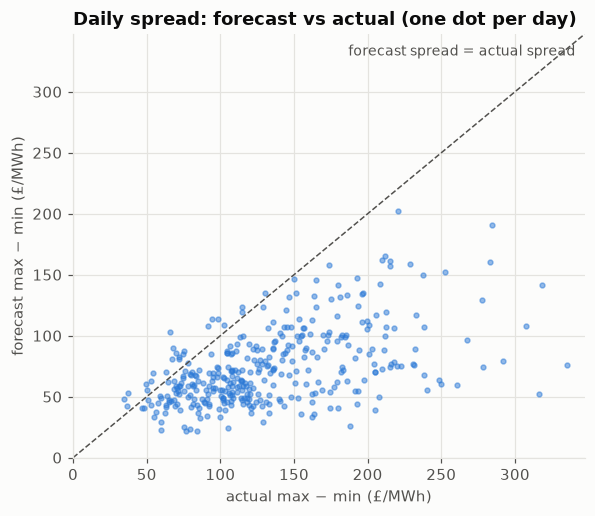

median daily spread: forecast £68, actual £122


In [5]:
spread = lambda s: s.max() - s.min()  # noqa: E731
days = lgbm.groupby("target_date").agg(forecast=("p50", spread), actual=("actual", spread))

fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(days["actual"], days["forecast"], s=10, color=style.BLUE, alpha=0.5)
lim = [0, np.percentile(days["actual"], 99)]
ax.plot(lim, lim, color=style.TEXT_2, linewidth=1, linestyle="--")
ax.annotate(
    "forecast spread = actual spread",
    (lim[1], lim[1]),
    xytext=(-6, -14),
    textcoords="offset points",
    ha="right",
    color=style.TEXT_2,
    fontsize=9,
)
ax.set(
    title="Daily spread: forecast vs actual (one dot per day)",
    xlabel="actual max − min (£/MWh)",
    ylabel="forecast max − min (£/MWh)",
    xlim=lim,
    ylim=lim,
)
plt.show()
print(
    f"median daily spread: forecast £{days.forecast.median():.0f}, actual £{days.actual.median():.0f}"
)

Almost every day sits below the diagonal. That's what a median forecast does when the target
is noisy: it predicts the *typical* value for each half-hour, and averaging pulls the peaks
down and the troughs up. The battery earns from the spread, so a flattened forecast means
fewer and smaller trades: cautious, but leaving most of the money behind.

## 5. What the model relies on

SHAP values split each prediction into contributions from each input. LightGBM computes them
exactly for trees (`pred_contrib=True`); the average absolute contribution is a fair measure
of how much each input moves the forecast.

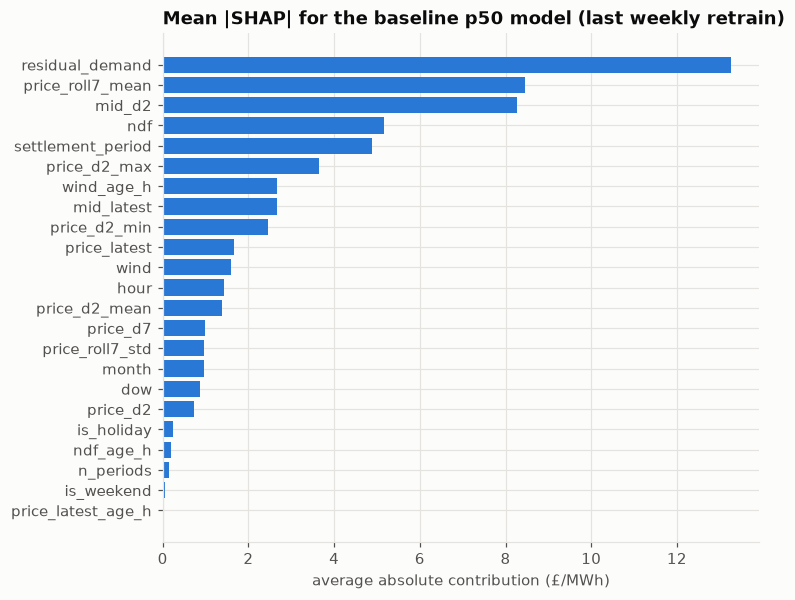

In [6]:
model = load_model(store, "backtest/experiments/baseline/model", MODELS)
test_days = sorted(set(lgbm["target_date"]))
X_test, _, _ = feature_table(history, test_days, decision_at=pd.Timestamp("09:00").time())
X_model = X_test[model.features]
contrib = model.boosters["p50"].predict(X_model, pred_contrib=True)[:, :-1]  # last col = bias
importance = pd.Series(np.abs(contrib).mean(axis=0), index=X_model.columns).sort_values()

fig, ax = plt.subplots(figsize=(7, 6))
ax.barh(importance.index, importance.values, color=style.BLUE)
ax.set(
    title="Mean |SHAP| for the baseline p50 model (last weekly retrain)",
    xlabel="average absolute contribution (£/MWh)",
)
plt.show()

The model leans on recent price levels (7-day average at this time of day, the exchange price
two days earlier) and on demand minus wind. Nothing describes solar, gas prices, or the
system's expected shortfall, so on days when those move the price, the model can only fall
back to "what's typical for this time of day".

## 6. The days that cost the most

The worst 10% of days (36) account for 29% of the £ left on the table.


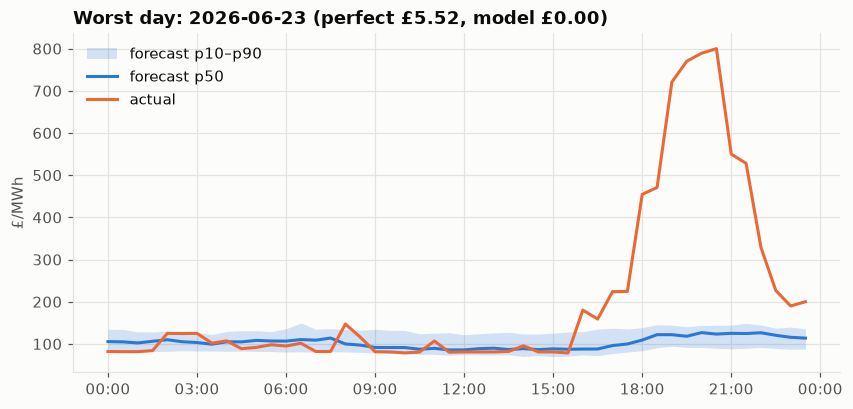

In [7]:
wide = daily.pivot(index="target_date", columns="strategy", values="value_gbp")
shortfall = (wide["perfect"] - wide["lgbm_quantile"]).sort_values(ascending=False)
share_top = shortfall.head(36).sum() / shortfall.sum()
print(f"The worst 10% of days (36) account for {share_top:.0%} of the £ left on the table.")

worst = shortfall.index[0]
d = lgbm[lgbm.target_date == worst].set_index("start_time")
t = d.index.tz_convert(LONDON)
fig, ax = plt.subplots()
ax.fill_between(
    t, d["p10"], d["p90"], color=style.BLUE, alpha=0.2, linewidth=0, label="forecast p10–p90"
)
ax.plot(t, d["p50"], color=style.BLUE, label="forecast p50")
ax.plot(t, d["actual"], color=style.ORANGE, label="actual")
ax.set(
    title=f"Worst day: {worst} (perfect £{wide.loc[worst, 'perfect']:.2f}, "
    f"model £{wide.loc[worst, 'lgbm_quantile']:.2f})",
    ylabel="£/MWh",
)
ax.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%H:%M", tz=LONDON))
ax.legend(loc="upper left")
plt.show()

A small number of volatile days carry much of the missed value, and on them the forecast
looks like an ordinary day while the actual price swings far outside the band.

## Takeaways → what to change

| Finding | Change | Checkpoint |
|---|---|---|
| No view of solar, which drives midday prices and negatives | add the embedded solar forecast | B |
| Band too narrow, misses lopsided upward | calibrate quantiles on the validation window | C |
| Default settings, never tuned | tune on the validation window | C |
| Flattened shape is inherent to forecasting this noisy price a day ahead | trade a price that clears in advance; treat imbalance as a later layer | D |